# Data preprocessing

In [31]:
import pandas as pd
import numpy as np
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
import matplotlib.pyplot as plt
from transformers import TrainerCallback
import os
import csv
import torch, torch.nn as nn
import pandas as pd
from transformers import AutoTokenizer, T5EncoderModel, TrainingArguments, Trainer, default_data_collator,TrainerCallback
from peft import LoraConfig, get_peft_model
from trl import SFTTrainer
from datasets import load_dataset
from sklearn.metrics import mean_absolute_error, r2_score

In [32]:
test_df = pd.read_csv('./data/tg_test_df.csv')

In [33]:
test_df['tg_scaled'] = test_df['tg_scaled'].astype(float)

test_data=test_df[['HAPPY','tg_scaled']]
test_data.columns =['text','label']
test_data.to_csv('happy_tg/test_df.csv',index=False)
test_data.to_json("happy_tg/test_df.jsonl", orient="records", lines=True)

# Model performance

In [34]:
model_id = "GT4SD/multitask-text-and-chemistry-t5-base-standard"
tok = AutoTokenizer.from_pretrained(model_id, use_fast=False)

class T5Regressor(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.enc = encoder
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Linear(self.enc.config.d_model, 1)

    def forward(self, input_ids, attention_mask, labels=None):
        h = self.enc(input_ids, attention_mask).last_hidden_state  
        z = self.pool(h.transpose(1,2)).squeeze(-1)                
        y_hat = self.head(z).squeeze(-1)                           
        
        loss = None
        if labels is not None:
            loss = nn.functional.mse_loss(y_hat, labels.float()) 
        return {"loss": loss, "logits": y_hat}


    def state_dict(self, *args, **kwargs):
        # 모델의 원래 가중치들을 불러옴
        sd = super().state_dict(*args, **kwargs)
        # safetensors 중복 메모리 에러를 피하기 위해 가중치 하나를 복제(clone)
        if 'enc.shared.weight' in sd:
            sd['enc.shared.weight'] = sd['enc.shared.weight'].clone()
        return sd

C:\Users\fkfaj\anaconda3\envs\bkcs\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [35]:
def tokenize(batch):
    enc = tok(batch["text"],
              padding="max_length",
              truncation=True,
              max_length=256)
    enc["labels"] = batch["label"]      # float → 그대로 tensor
    return enc


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.squeeze(predictions)
    
    mse = mean_squared_error(labels, predictions)
    mae = mean_absolute_error(labels, predictions)
    
    return {"mse": mse, "mae": mae}

class EpochCSVLogger(TrainerCallback):
    def __init__(self, log_path):
        self.log_path = log_path
        # 파일이 없으면 헤더 생성
        if not os.path.exists(self.log_path):
            with open(self.log_path, mode='w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(['epoch', 'train_loss', 'eval_loss',  'eval_mae'])

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if metrics:
            epoch = metrics.get('epoch', state.epoch)
            # 최근 학습 로그에서 train loss 가져오기
            logs = state.log_history
            train_loss = next((log['loss'] for log in reversed(logs) if 'loss' in log), 'N/A')
            eval_loss = metrics.get('eval_loss', 'N/A')
            eval_mse = metrics.get('eval_mse', 'N/A')
            eval_mae = metrics.get('eval_mae', 'N/A')

            with open(self.log_path, mode='a', newline='') as f:
                writer = csv.writer(f)
                writer.writerow([epoch, train_loss, eval_loss, eval_mae])

In [36]:
args = TrainingArguments(
    output_dir='happy_tg',
    per_device_train_batch_size=20,
    per_device_eval_batch_size=10,
    gradient_accumulation_steps=1,
    num_train_epochs=400,
    learning_rate=5e-4,
    lr_scheduler_type="cosine",
    warmup_steps=100,                    
    fp16=False,
    evaluation_strategy="epoch",         # eval_strategy 대신 구버전 호환 이름 사용
    save_strategy="epoch",
    logging_strategy='epoch',
    report_to="none",
    #save_safetensors=False,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_mse",
    greater_is_better=False,
    dataloader_num_workers=2,     
    dataloader_pin_memory=True,
)


In [37]:
from safetensors.torch import load_file

device = 'cpu'
tok = AutoTokenizer.from_pretrained(model_id, use_fast=False)
enc = T5EncoderModel.from_pretrained(model_id) 
happy_tokens = ["B", "Bn", "Bc", "Bh", "Nbb", "Ma", "H", "Co", "Ct", "Cf", "Cq", "Bp", "Bm", "Bpc", "Bpy", "Bpt", "Mat", "#", "@", "&","*","C@Od",]
tok.add_tokens(happy_tokens)

enc.resize_token_embeddings(len(tok))


model = T5Regressor(enc)
f_dir='happy_tg'

model = model.to(device)
    

checkpoint_dir = 'happy_tg/checkpoint-6016'

# 가중치(Weights) 파일 경로 찾기 및 불러오기
bin_path = os.path.join(checkpoint_dir, "pytorch_model.bin")
safe_path = os.path.join(checkpoint_dir, "model.safetensors")
# 커스텀 모델에 학습된 가중치 적용

if os.path.exists(safe_path):
    model.load_state_dict(load_file(safe_path))
elif os.path.exists(bin_path):
    model.load_state_dict(torch.load(bin_path, map_location=device))


model.to(device)
model.eval()  

print("모델 로드 및 준비 완료!")


trainer = Trainer(
    model=model,
    args=args
)





모델 로드 및 준비 완료!


In [38]:
ds = load_dataset("json", data_files={"test":'./happy_tg/test_df.jsonl'})
ds = ds.map(tokenize, batched=True, remove_columns=["text", "label"])

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/235 [00:00<?, ? examples/s]

In [39]:
test_pred = trainer.predict(ds["test"])

In [40]:
import numpy as np


test_pred_K = (test_pred[0].reshape(-1, 1) * 92.34104534972987) + 331.15222534912186
test_labels_K = (np.array(ds["test"]["labels"]).reshape(-1, 1)* 92.34104534972987) + 331.15222534912186

MAE: 28.343, RMSE: 44.760, R2: 0.738


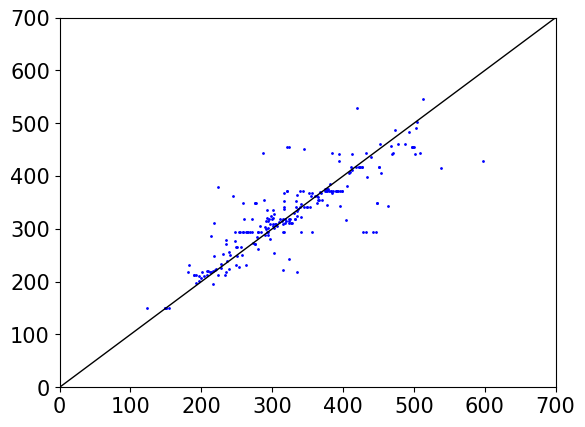

In [41]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import matplotlib.pyplot as plt

ax = plt


ax.scatter(test_labels_K,test_pred_K , s=1,c='blue')
ax.tick_params(axis='both', labelsize=15)
plt.xlim(0, 700)
plt.ylim(0, 700)

ax.plot((0, 700), (0, 700), c="black", linewidth=1)

test_mae = mean_absolute_error(test_labels_K,test_pred_K)
test_r2 = r2_score(test_labels_K,test_pred_K)
test_rmse = root_mean_squared_error(test_labels_K,test_pred_K)


print(f"MAE: {test_mae:.3f}, RMSE: {test_rmse:.3f}, R2: {test_r2:.3f}")

In [42]:
import pandas as pd

# flatten()을 사용하여 (235, 1)을 (235,) 형태의 1차원으로 변환
df = pd.DataFrame({
    'test_label': pd.Series(test_labels_K.flatten()),
    'test_pred': pd.Series(test_pred_K.flatten())
})

# 결과 확인
df.to_csv('./happy_result.csv', index=False)